In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
data_path = '/content/drive/MyDrive/Python for ML/dataset/cleaned_all_phones.csv'

In [3]:
import pandas as pd
import numpy as np
from scipy.stats.mstats import winsorize
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv(data_path)
display(df.head())

,phone_name,brand,os,inches,resolution,battery,battery_type,ram(GB),announcement_date,weight(g),...,video_1080p,video_4K,video_8K,video_30fps,video_60fps,video_120fps,video_240fps,video_480fps,video_960fps,price(USD)
0,Y6II Compact,Huawei,Android 5.1,5.0,720x1280,2200,Li-Po,2,2016-09-01,140.0,...,False,False,False,True,False,False,False,False,False,120.0
1,K20 plus,LG,Android 7.0,5.3,720x1280,2700,Li-Ion,2,2016-12-01,140.0,...,True,False,False,True,False,False,False,False,False,100.0
2,P8 Lite (2017),Huawei,Android 7.0,5.2,1080x1920,3000,Li-Ion,4,2017-01-01,147.0,...,True,False,False,True,False,False,False,False,False,420.0
3,Redmi Note 4,Xiaomi,Android 6.0,5.5,1080x1920,4100,Li-Po,4,2017-01-01,165.0,...,True,False,False,True,False,True,False,False,False,150.0
4,P10,Huawei,Android 7.0,5.1,1080x1920,3200,Li-Ion,4,2017-02-01,145.0,...,True,True,False,True,True,False,False,False,False,420.0


In [5]:
print(df.info())
print()
print(df.describe().T)
print()
print(df.describe(include='object').T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1512 entries, 0 to 1511
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   phone_name         1512 non-null   object 
 1   brand              1512 non-null   object 
 2   os                 1512 non-null   object 
 3   inches             1512 non-null   float64
 4   resolution         1512 non-null   object 
 5   battery            1512 non-null   int64  
 6   battery_type       1512 non-null   object 
 7   ram(GB)            1512 non-null   int64  
 8   announcement_date  1512 non-null   object 
 9   weight(g)          1512 non-null   float64
 10  storage(GB)        1512 non-null   int64  
 11  video_720p         1512 non-null   bool   
 12  video_1080p        1512 non-null   bool   
 13  video_4K           1512 non-null   bool   
 14  video_8K           1512 non-null   bool   
 15  video_30fps        1512 non-null   bool   
 16  video_60fps        1512 

# Xử lý outlier + encode


Xóa đi Tizen 3.0 (do đã bị khai tử và chỉ có 1 trong dataset)

In [6]:
df = df[df['os'] != 'Tizen 3.0']

Log Transform cho "price(USD)", "battery", "storage(GB)" và "weight(g)"

In [7]:
def apply_log_transform(df, col):
    df[col + '_log'] = np.log1p(df[col])  # log1p là log(x + 1) để tránh log(0)
    print(f'{col}: log-transformed to {col + "_log"}')
    return df

In [8]:
df = apply_log_transform(df, 'price(USD)')
df = apply_log_transform(df, 'weight(g)')
df = apply_log_transform(df, 'battery')
df = apply_log_transform(df, 'storage(GB)')

price(USD): log-transformed to price(USD)_log
weight(g): log-transformed to weight(g)_log
battery: log-transformed to battery_log
storage(GB): log-transformed to storage(GB)_log


Dùng winsorization nhẹ (ví dụ: giới hạn 1%/99%) để giảm tác động của outlier mà không xóa dòng.

In [9]:
df['inches_winsorization'] = winsorize(df['inches'], limits=[0.01, 0.01])

Phân nhóm RAM theo phân khúc: giá rẻ, trung, cao cấp - theo hệ điều hành (iOS sẽ tốt hơn android cùng lượng ram)

In [10]:
def group_ram(row):
    brand = row['brand'].lower()
    ram = row['ram(GB)']

    if 'apple' in brand:
        if ram <= 3:
            return 0  # Giá rẻ
        elif ram == 4:
            return 1  # Trung cấp
        else:
            return 2  # Cao cấp
    else:  # Android
        if ram <= 4:
            return 0  # Giá rẻ
        elif ram <= 8:
            return 1  # Trung cấp
        else:
            return 2  # Cao cấp

# Áp dụng hàm group_ram vào DataFrame
df['ram_group_encoded'] = df.apply(group_ram, axis=1)

In [11]:
df.head()

,phone_name,brand,os,inches,resolution,battery,battery_type,ram(GB),announcement_date,weight(g),...,video_240fps,video_480fps,video_960fps,price(USD),price(USD)_log,weight(g)_log,battery_log,storage(GB)_log,inches_winsorization,ram_group_encoded
0,Y6II Compact,Huawei,Android 5.1,5.0,720x1280,2200,Li-Po,2,2016-09-01,140.0,...,False,False,False,120.0,4.795791,4.948760,7.696667,2.833213,5.0,0
1,K20 plus,LG,Android 7.0,5.3,720x1280,2700,Li-Ion,2,2016-12-01,140.0,...,False,False,False,100.0,4.615121,4.948760,7.901377,2.833213,5.3,0
2,P8 Lite (2017),Huawei,Android 7.0,5.2,1080x1920,3000,Li-Ion,4,2017-01-01,147.0,...,False,False,False,420.0,6.042633,4.997212,8.006701,2.833213,5.2,0
3,Redmi Note 4,Xiaomi,Android 6.0,5.5,1080x1920,4100,Li-Po,4,2017-01-01,165.0,...,False,False,False,150.0,5.017280,5.111988,8.318986,3.496508,5.5,0
4,P10,Huawei,Android 7.0,5.1,1080x1920,3200,Li-Ion,4,2017-02-01,145.0,...,False,False,False,420.0,6.042633,4.983607,8.071219,3.496508,5.1,0


In [12]:
count_apple = df[df['ram_group_encoded'] == 3].shape[0]
print(count_apple)

0


Inches + Resolution (màn hình + độ phân giải)

In [13]:
# Tách resolution thành width và height
df[['width', 'height']] = df['resolution'].str.lower().str.extract(r'(\d+)[x×](\d+)').astype(float)

# Tính PPI
df['ppi'] = ((df['width']**2 + df['height']**2)**0.5) / df['inches']
df = apply_log_transform(df, 'ppi') #Log transform cho ppi

ppi: log-transformed to ppi_log


Brand: theo cụm giá cao -> thấp

In [14]:
brand_price_mean = df.groupby('brand')['price(USD)'].mean()
brand_price_mean

,price(USD)
brand,
Apple,680.037273
Google,448.082632
Honor,358.317984
Huawei,403.913650
LG,264.000000
Lenovo,245.116279
OnePlus,421.010723
Oppo,341.332000
Realme,242.407732


In [15]:
df['brand_encoded'] = df['brand'].map(brand_price_mean)
df.drop('brand', axis=1, inplace=True)
df = apply_log_transform(df, 'brand_encoded')

brand_encoded: log-transformed to brand_encoded_log


os: theo cụm

In [16]:
def categorize_os(os):
    os = str(os).lower()
    if any(v in os for v in ['android 5', 'android 6', 'android 7', 'android 8','ios 11',  'emui 12']):
        return 'old'
    elif any(v in os for v in ['android 9', 'android 10', 'android 11', 'ios 12', 'ios 13', 'ios 14', 'emui 13']):
        return 'mid'
    elif any(v in os for v in ['android 12', 'android 13', 'ios 15', 'ios 16']):
        return 'new'
    else:
        return 'unknown'

df['os_group'] = df['os'].apply(categorize_os)

In [17]:
os_group_mapping = {'old': 0, 'mid': 1, 'new': 2, 'unknown': -1}
df['os_group_encoded'] = df['os_group'].map(os_group_mapping)
df.drop(['os', 'os_group'], axis=1, inplace=True)

battery_type: Li-Po 0; Li-Ion 1

In [18]:
battery_mapping = {'Li-Po': 0, 'Li-Ion': 1}
df['battery_type_encoded'] = df['battery_type'].map(battery_mapping)
df.drop('battery_type', axis=1, inplace=True)

các cột camera feature: TRUE:1 ,FALSE:0

In [19]:
video_cols = [
    'video_720p', 'video_1080p', 'video_4K', 'video_8K',
    'video_30fps', 'video_60fps', 'video_120fps',
    'video_240fps', 'video_480fps', 'video_960fps'
]

# Convert True/False to int (1/0)
df[video_cols] = df[video_cols].astype(int)

In [20]:
df.head()

,phone_name,inches,resolution,battery,ram(GB),announcement_date,weight(g),storage(GB),video_720p,video_1080p,...,inches_winsorization,ram_group_encoded,width,height,ppi,ppi_log,brand_encoded,brand_encoded_log,os_group_encoded,battery_type_encoded
0,Y6II Compact,5.0,720x1280,2200,2,2016-09-01,140.0,16,1,0,...,5.0,0,720.0,1280.0,293.720956,5.686029,403.913650,6.003674,0,0
1,K20 plus,5.3,720x1280,2700,2,2016-12-01,140.0,16,0,1,...,5.3,0,720.0,1280.0,277.095242,5.627964,264.000000,5.579730,0,1
2,P8 Lite (2017),5.2,1080x1920,3000,4,2017-01-01,147.0,16,0,1,...,5.2,0,1080.0,1920.0,423.635994,6.051232,403.913650,6.003674,0,1
3,Redmi Note 4,5.5,1080x1920,4100,4,2017-01-01,165.0,32,1,1,...,5.5,0,1080.0,1920.0,400.528576,5.995279,306.254129,5.727675,0,0
4,P10,5.1,1080x1920,3200,4,2017-02-01,145.0,32,1,1,...,5.1,0,1080.0,1920.0,431.942582,6.070605,403.913650,6.003674,0,1


In [21]:
count_apple = df[df['os_group_encoded'] == -1].shape[0]
print(count_apple)

3


#So sánh boxplot trước và sau xử lí outlier + encode

In [22]:
columns = [
    'price(USD)_log', 'price(USD)',
    'weight(g)_log', 'weight(g)',
    'inches_winsorization', 'inches',
    'ppi_log', 'ppi',
    'battery_log', 'battery',
    'ram_group_encoded', 'ram(GB)',
    'storage(GB)_log', 'storage(GB)'
]

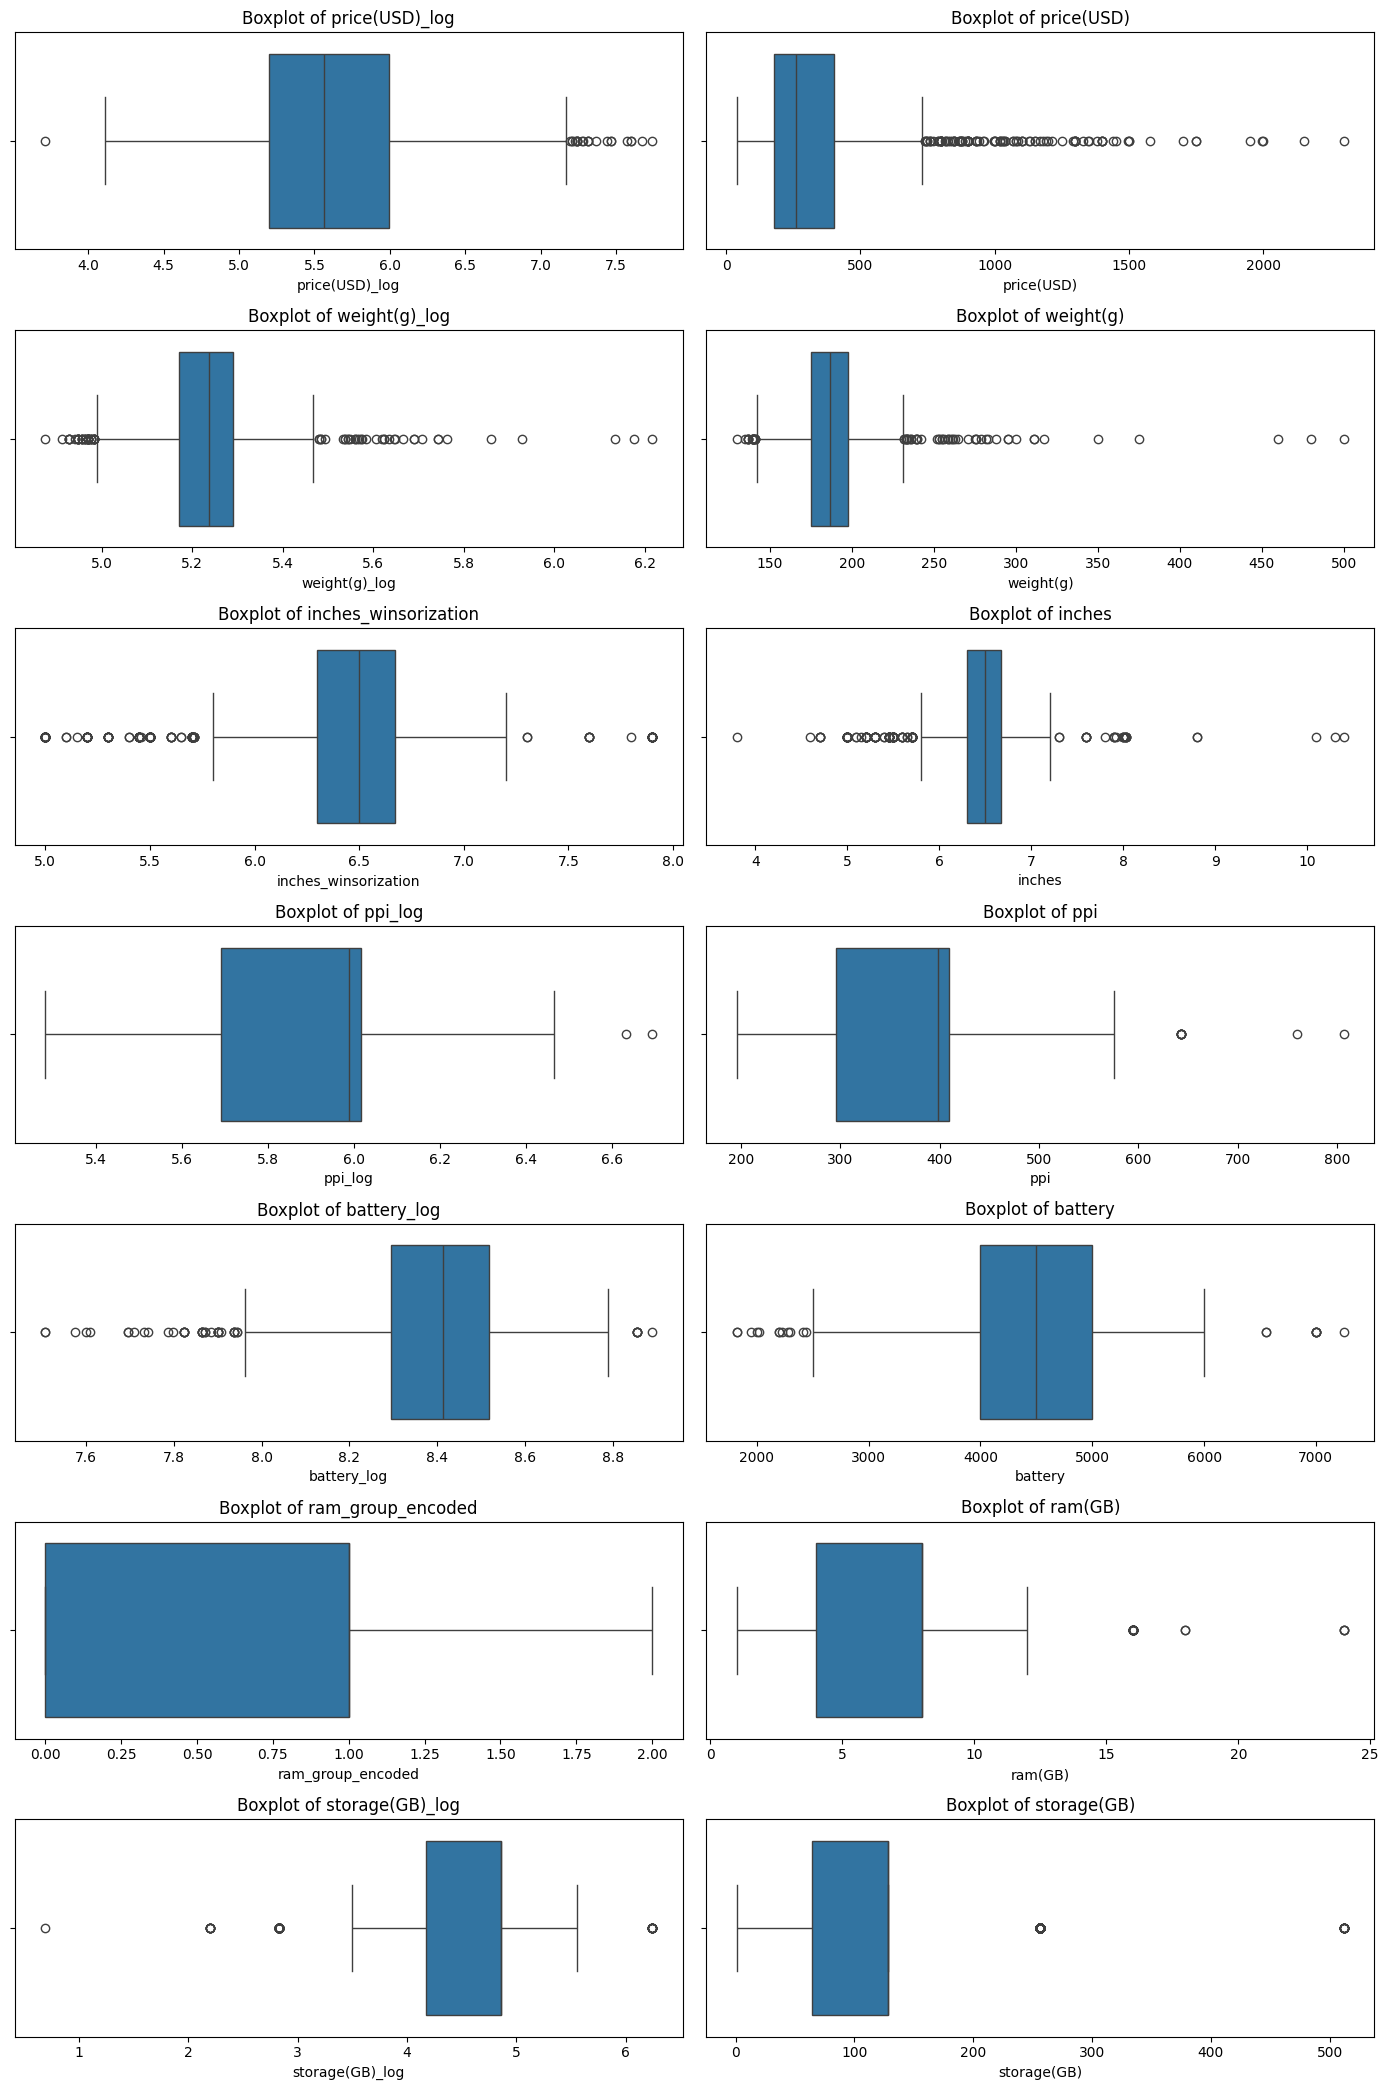

In [23]:
# Tính số hàng cần để chia 2 cột mỗi hàng
n_cols = 2
n_rows = (len(columns) + 1) // n_cols  # Làm tròn lên

# Tạo figure và axes
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, n_rows * 3))

# Flatten axes để dễ duyệt (phòng trường hợp 1 hàng thì axes không phải mảng)
axes = axes.flatten()

# Vẽ từng boxplot
for i, col in enumerate(columns):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(f"Boxplot of {col}", fontsize=12)
    axes[i].set_xlabel(col)

# Ẩn plot thừa (nếu có)
for j in range(len(columns), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

#Chọn đặc trưng

##Chọn theo độ tương quan cao

Kiểm tra tương quan với price
 Loại bỏ các feature có tương quan gần 0 với price(USD)
(dưới ±0.05 thường là nhiễu hoặc không có ý nghĩa)

In [24]:
# Chọn numeric features
numeric_features = [
    'ppi_log', 'battery', 'storage(GB)_log',
    'brand_encoded_log', 'ram_group_encoded',
    'os_group_encoded'
]

# + Video features (binary)
video_features = [col for col in df.columns if col.startswith('video_')]

# Gộp lại
all_features = numeric_features + video_features

# Tính tương quan
corr = df[all_features + ['price(USD)']].corr()['price(USD)'].sort_values(ascending=False)

# Hiển thị tương quan
print(corr)

price(USD)           1.000000
ram_group_encoded    0.328620
storage(GB)_log      0.321069
video_4K             0.312284
video_720p           0.311136
video_60fps          0.279141
ppi_log              0.263969
video_240fps         0.251164
brand_encoded_log    0.249169
video_8K             0.218897
video_120fps         0.176438
video_960fps         0.169542
os_group_encoded     0.143488
video_480fps         0.059574
video_1080p         -0.008059
battery             -0.008801
video_30fps         -0.186608
Name: price(USD), dtype: float64


Kiểm tra đa cộng tuyến

In [25]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import pandas as pd

X = df[all_features].copy()
X = add_constant(X)

vif = pd.DataFrame()
vif["Feature"] = X.columns
vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif)

              Feature          VIF
0               const  2899.271430
1             ppi_log     1.970801
2             battery     1.774085
3     storage(GB)_log     2.984545
4   brand_encoded_log     1.208812
5   ram_group_encoded     2.500066
6    os_group_encoded     1.716738
7          video_720p    41.164554
8         video_1080p     1.496946
9            video_4K    42.313589
10           video_8K     1.199928
11        video_30fps     1.510084
12        video_60fps     3.316901
13       video_120fps     2.450327
14       video_240fps     2.682838
15       video_480fps     1.050447
16       video_960fps     1.538391


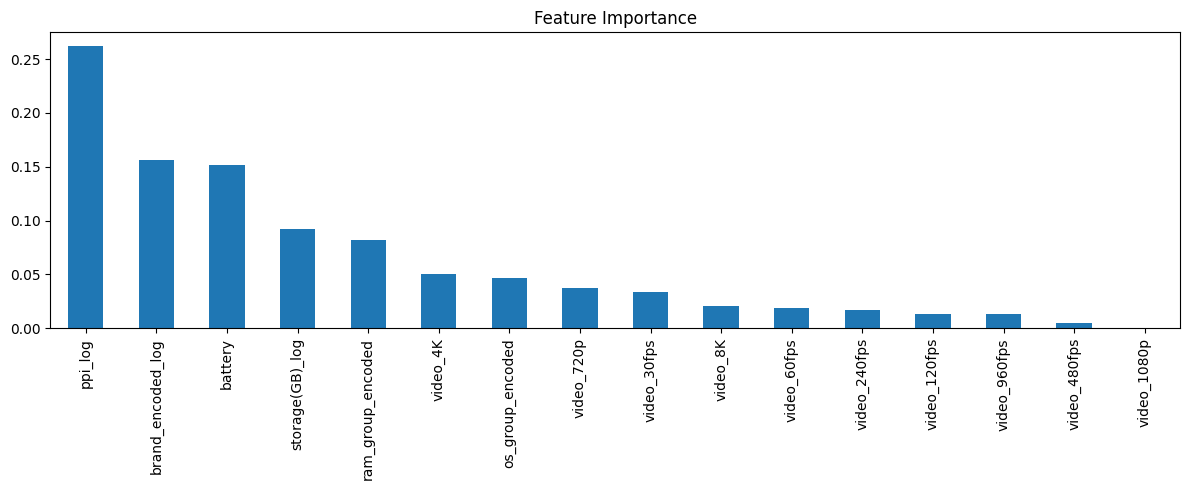

In [26]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor()
model.fit(df[all_features], df['price(USD)'])

feat_importance = pd.Series(model.feature_importances_, index=all_features)
feat_importance.sort_values(ascending=False).plot(kind='bar', figsize=(12, 5), title='Feature Importance')
plt.tight_layout()
plt.show()

In [29]:
#Tách 'ressolution' rồi xóa
df[['width', 'height']] = df['resolution'].str.lower().str.strip().str.split('x', expand=True).astype(int)
df.drop(columns=['resolution'], inplace=True)

In [30]:
# Chuyển 'announcement_date' về dạng datetime
df['announcement_date'] = pd.to_datetime(df['announcement_date'], errors='coerce')

# Tạo cột 'announcement_year'
df['announcement_year'] = df['announcement_date'].dt.year

#Xóa 'announcement_date'
df.drop(columns=['announcement_date'], inplace=True)

In [31]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error # Import mean_absolute_error
from sklearn.model_selection import train_test_split

# Drop 'phone_name' column
X = df.drop(['price(USD)', 'phone_name'], axis=1)
y = df['price(USD)']

xtrain, xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=42)

from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(random_state=42)
rf.fit(xtrain, ytrain)
rf_pred = rf.predict(xtest)
mean_absolute_error(ytest, rf_pred)

1.668322574257413

##Chạy SelectKBest, RFE, Feature Importance và so sánh model

In [ ]:
from sklearn.feature_selection import SelectKBest, f_regression, RFE
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# --- STEP 1: Chuẩn bị ---
# Giả sử bạn đã có df chứa đầy đủ cột:
# ['price(USD)', 'ppi_log', 'battery', 'storage(GB)_log', 'brand_encoded_log',
#  'ram_group_encoded', 'os_group_encoded', 'video_720p', ..., 'video_960fps']

numeric_features = [
    'ppi_log', 'battery', 'storage(GB)_log',
    'brand_encoded_log', 'ram_group_encoded',
    'os_group_encoded'
]

video_features = [col for col in df.columns if col.startswith('video_')]
all_features = numeric_features + video_features
target = 'price(USD)'

# Tách train/test
X = df[all_features]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- STEP 2: Feature selection ---

## 2.1 SelectKBest
selector_kbest = SelectKBest(score_func=f_regression, k='all')
selector_kbest.fit(X_train, y_train)
kbest_scores = pd.Series(selector_kbest.scores_, index=X_train.columns)
print("Top features từ SelectKBest:")
print(kbest_scores.sort_values(ascending=False))

## 2.2 RFE với Linear Regression
model_lr = LinearRegression()
rfe = RFE(estimator=model_lr, n_features_to_select=10)
rfe.fit(X_train, y_train)
print("Top 10 features được chọn bởi RFE:")
print(X_train.columns[rfe.support_].tolist())

## 2.3 Random Forest Feature Importance
model_rf = RandomForestRegressor(random_state=42)
model_rf.fit(X_train, y_train)
rf_importance = pd.Series(model_rf.feature_importances_, index=X_train.columns)
print("Feature Importance từ Random Forest:")
print(rf_importance.sort_values(ascending=False))

# --- STEP 3: So sánh mô hình ---

## (a) Dùng tất cả features
y_pred_all = model_rf.predict(X_test)
# Thay đổi dòng này:
# rmse_all = mean_squared_error(y_test, y_pred_all, squared=False)
# Thành:
rmse_all = np.sqrt(mean_squared_error(y_test, y_pred_all)) # Calculate RMSE using NumPy
print(f"RMSE khi dùng tất cả features: {rmse_all:.2f}")

## (b) Không dùng video features
X_train_no_video = X_train[numeric_features]
X_test_no_video = X_test[numeric_features]
model_no_video = RandomForestRegressor(random_state=42)
model_no_video.fit(X_train_no_video, y_train)
y_pred_no_video = model_no_video.predict(X_test_no_video)
rmse_no_video = np.sqrt(mean_squared_error(y_test, y_pred_no_video)) # Calculate RMSE using NumPy
print(f"RMSE khi không dùng video features: {rmse_no_video:.2f}")
